# 03. Eksperimen lengkap (skenario A, A2, B, C)

Memanggil `main()` dari `src/run_experiments.py` (satu-satunya tempat logika skenario) dan menulis hasilnya ke `results_rerun/` dan `figures_rerun/` (folder ini di-ignore git) supaya `results/` dan `figures/` yang dilaporkan di paper tidak tertimpa. Setelah selesai, hasilnya dibandingkan dengan `results/summary.csv`. Waktu jalan sekitar beberapa menit (Random Forest 5 seed dan 500 resampling bootstrap).

In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd().resolve().parent          # notebook dijalankan dari folder notebooks/
sys.path.insert(0, str(ROOT / "src"))
DATA = ROOT / "data" / "KaggleV2-May-2016.csv"
if not DATA.exists():
    raise FileNotFoundError(f"Taruh CSV Kaggle di {DATA} (lihat data/README.md).")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)

In [2]:
import contextlib, io
import run_experiments

OUT, FIG = ROOT / "results_rerun", ROOT / "figures_rerun"
argv_backup = sys.argv
sys.argv = ["run_experiments.py", "--data", str(DATA), "--out", str(OUT), "--figures", str(FIG)]
buf = io.StringIO()
try:
    with contextlib.redirect_stdout(buf):
        run_experiments.main()
finally:
    sys.argv = argv_backup
print(buf.getvalue()[:1500])

     split  n_rows start_date   end_date  no_show_rate  n_patients  pct_rows_patient_seen_in_earlier_split
     train   67360 2016-04-29 2016-05-20        0.2109       44253                                    0.00
validation   21175 2016-05-24 2016-06-01        0.1906       17246                                   49.93
      test   21986 2016-06-02 2016-06-08        0.1851       18212                                   55.47

Ringkasan (mean) tersimpan di C:\MATKUL SEMESTER 5\BINDO\ttki-p5-noshow\results_rerun\summary.csv



In [3]:
new = pd.read_csv(OUT / "summary.csv")
ref = pd.read_csv(ROOT / "results" / "summary.csv")
num = [c for c in ref.columns if c not in ("scenario", "model")]
assert (new[["scenario", "model"]].values == ref[["scenario", "model"]].values).all()
diff = (new[num].astype(float) - ref[num].astype(float)).abs().max().max()
print(f"Selisih maksimum terhadap results/summary.csv: {diff:.2e}")
assert diff < 1e-3, "hasil berbeda dari yang dilaporkan; periksa versi paket dan SHA-256 data"
cols = ["scenario", "model", "pr_auc_mean", "roc_auc_mean", "precision_at_10pct_mean", "recall_at_10pct_mean", "brier_mean", "ece_mean", "ece_quantile_mean"]
new[cols].round(3)

Selisih maksimum terhadap results/summary.csv: 0.00e+00


,scenario,model,pr_auc_mean,roc_auc_mean,precision_at_10pct_mean,recall_at_10pct_mean,brier_mean,ece_mean,ece_quantile_mean
0,A2_capacity_threshold,logreg,0.295,0.663,0.339,0.183,0.146,0.038,0.038
1,A2_capacity_threshold,random_forest,0.325,0.725,0.369,0.199,0.137,0.020,0.020
2,A_tuned_threshold,logreg,0.295,0.663,0.339,0.183,0.146,0.038,0.038
3,A_tuned_threshold,random_forest,0.325,0.725,0.369,0.199,0.137,0.020,0.020
4,B_isotonic,logreg,0.283,0.662,0.339,0.183,0.143,0.010,0.012
5,B_isotonic,random_forest,0.319,0.724,0.366,0.198,0.136,0.003,0.007
6,B_sigmoid,logreg,0.295,0.663,0.339,0.183,0.144,0.018,0.021
7,B_sigmoid,random_forest,0.325,0.725,0.369,0.199,0.138,0.028,0.029
8,baseline_thr0.5,logreg,0.295,0.663,0.339,0.183,0.146,0.038,0.038
9,baseline_thr0.5,random_forest,0.325,0.725,0.369,0.199,0.137,0.020,0.020


In [4]:
thr = new[new.scenario.isin(["baseline_thr0.5", "A_tuned_threshold", "A2_capacity_threshold"])]
thr[["scenario", "model", "threshold_mean", "precision_mean", "recall_mean", "f1_mean", "flagged_fraction_mean"]].round(3)

,scenario,model,threshold_mean,precision_mean,recall_mean,f1_mean,flagged_fraction_mean
0,A2_capacity_threshold,logreg,0.384,0.339,0.154,0.212,0.084
1,A2_capacity_threshold,random_forest,0.373,0.378,0.150,0.214,0.073
2,A_tuned_threshold,logreg,0.220,0.282,0.616,0.387,0.404
3,A_tuned_threshold,random_forest,0.237,0.296,0.724,0.420,0.454
8,baseline_thr0.5,logreg,0.500,0.411,0.041,0.075,0.019
9,baseline_thr0.5,random_forest,0.500,0.308,0.003,0.006,0.002


## Gambar

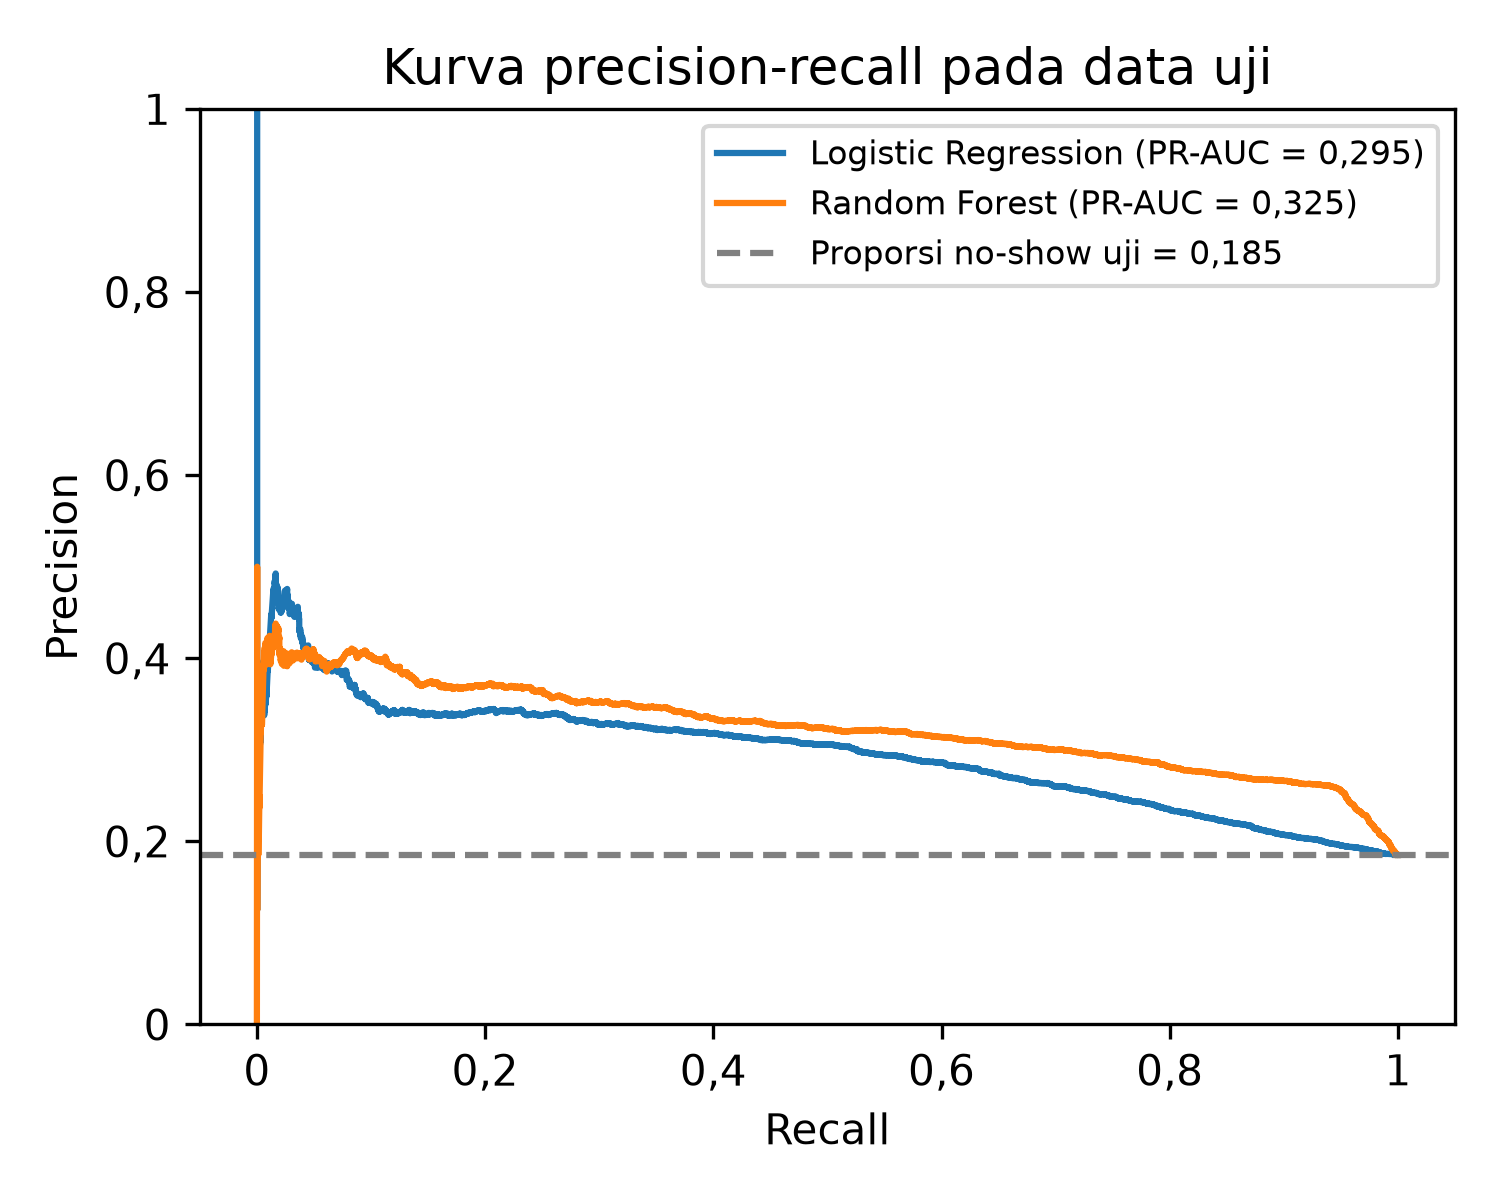

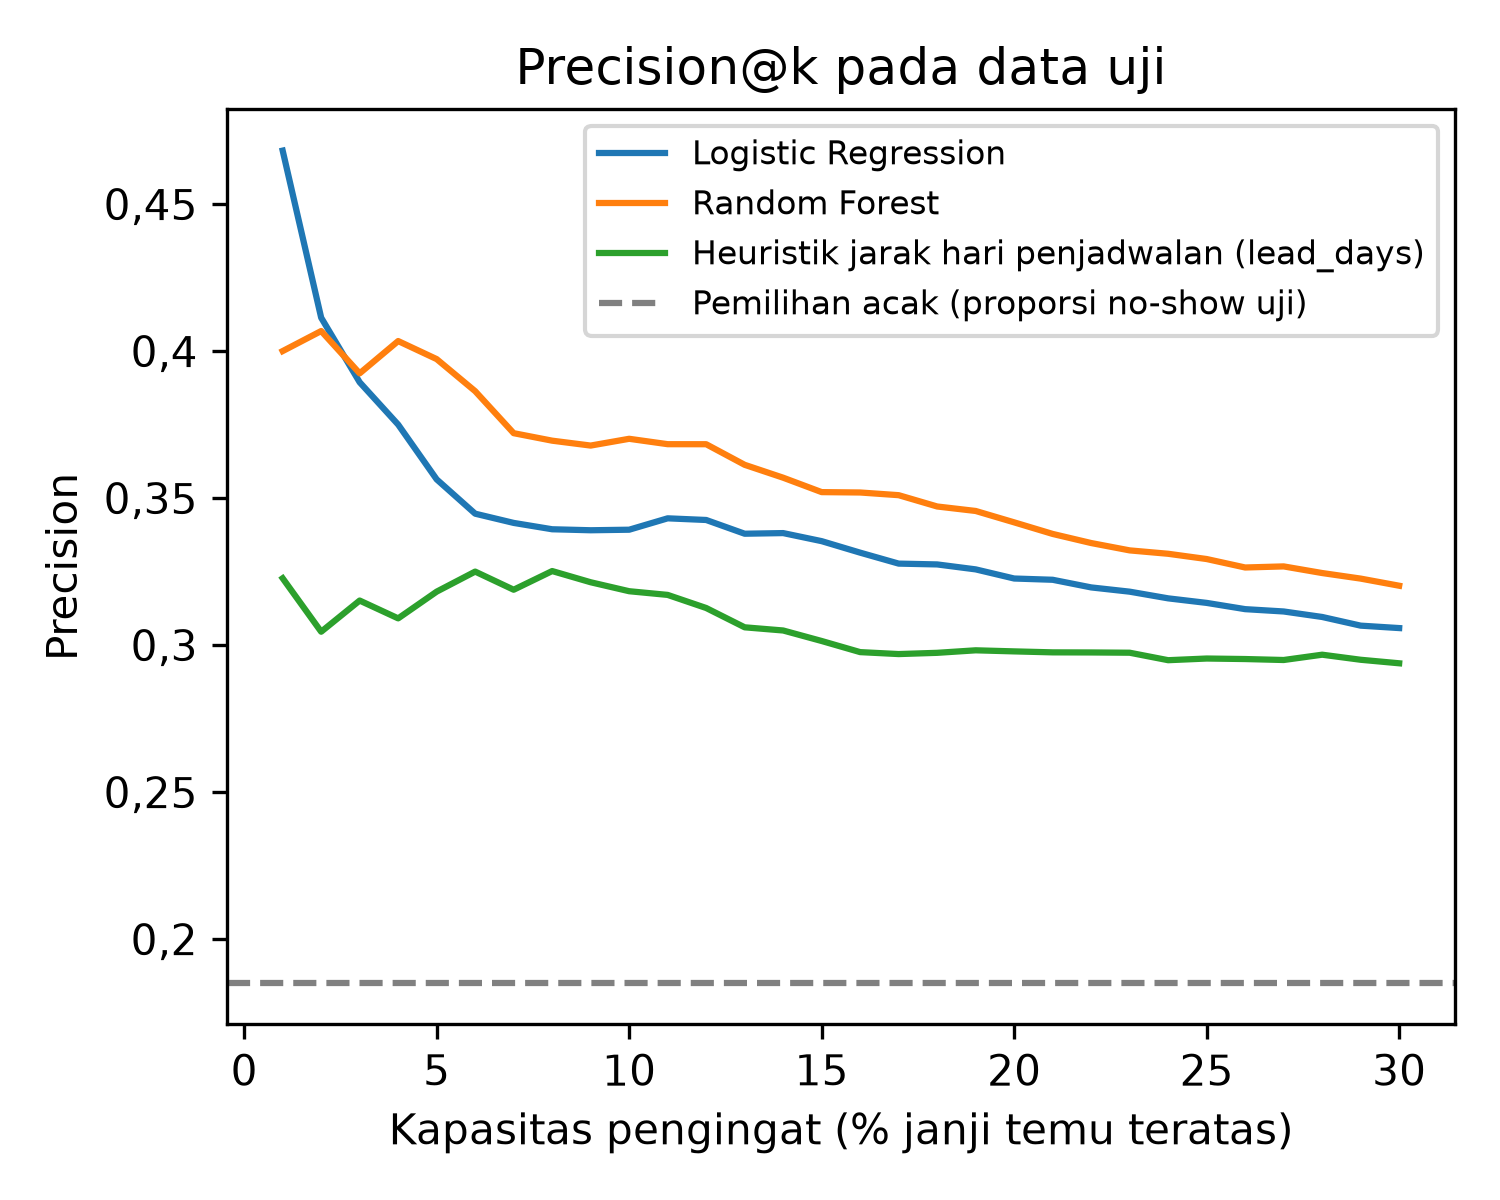

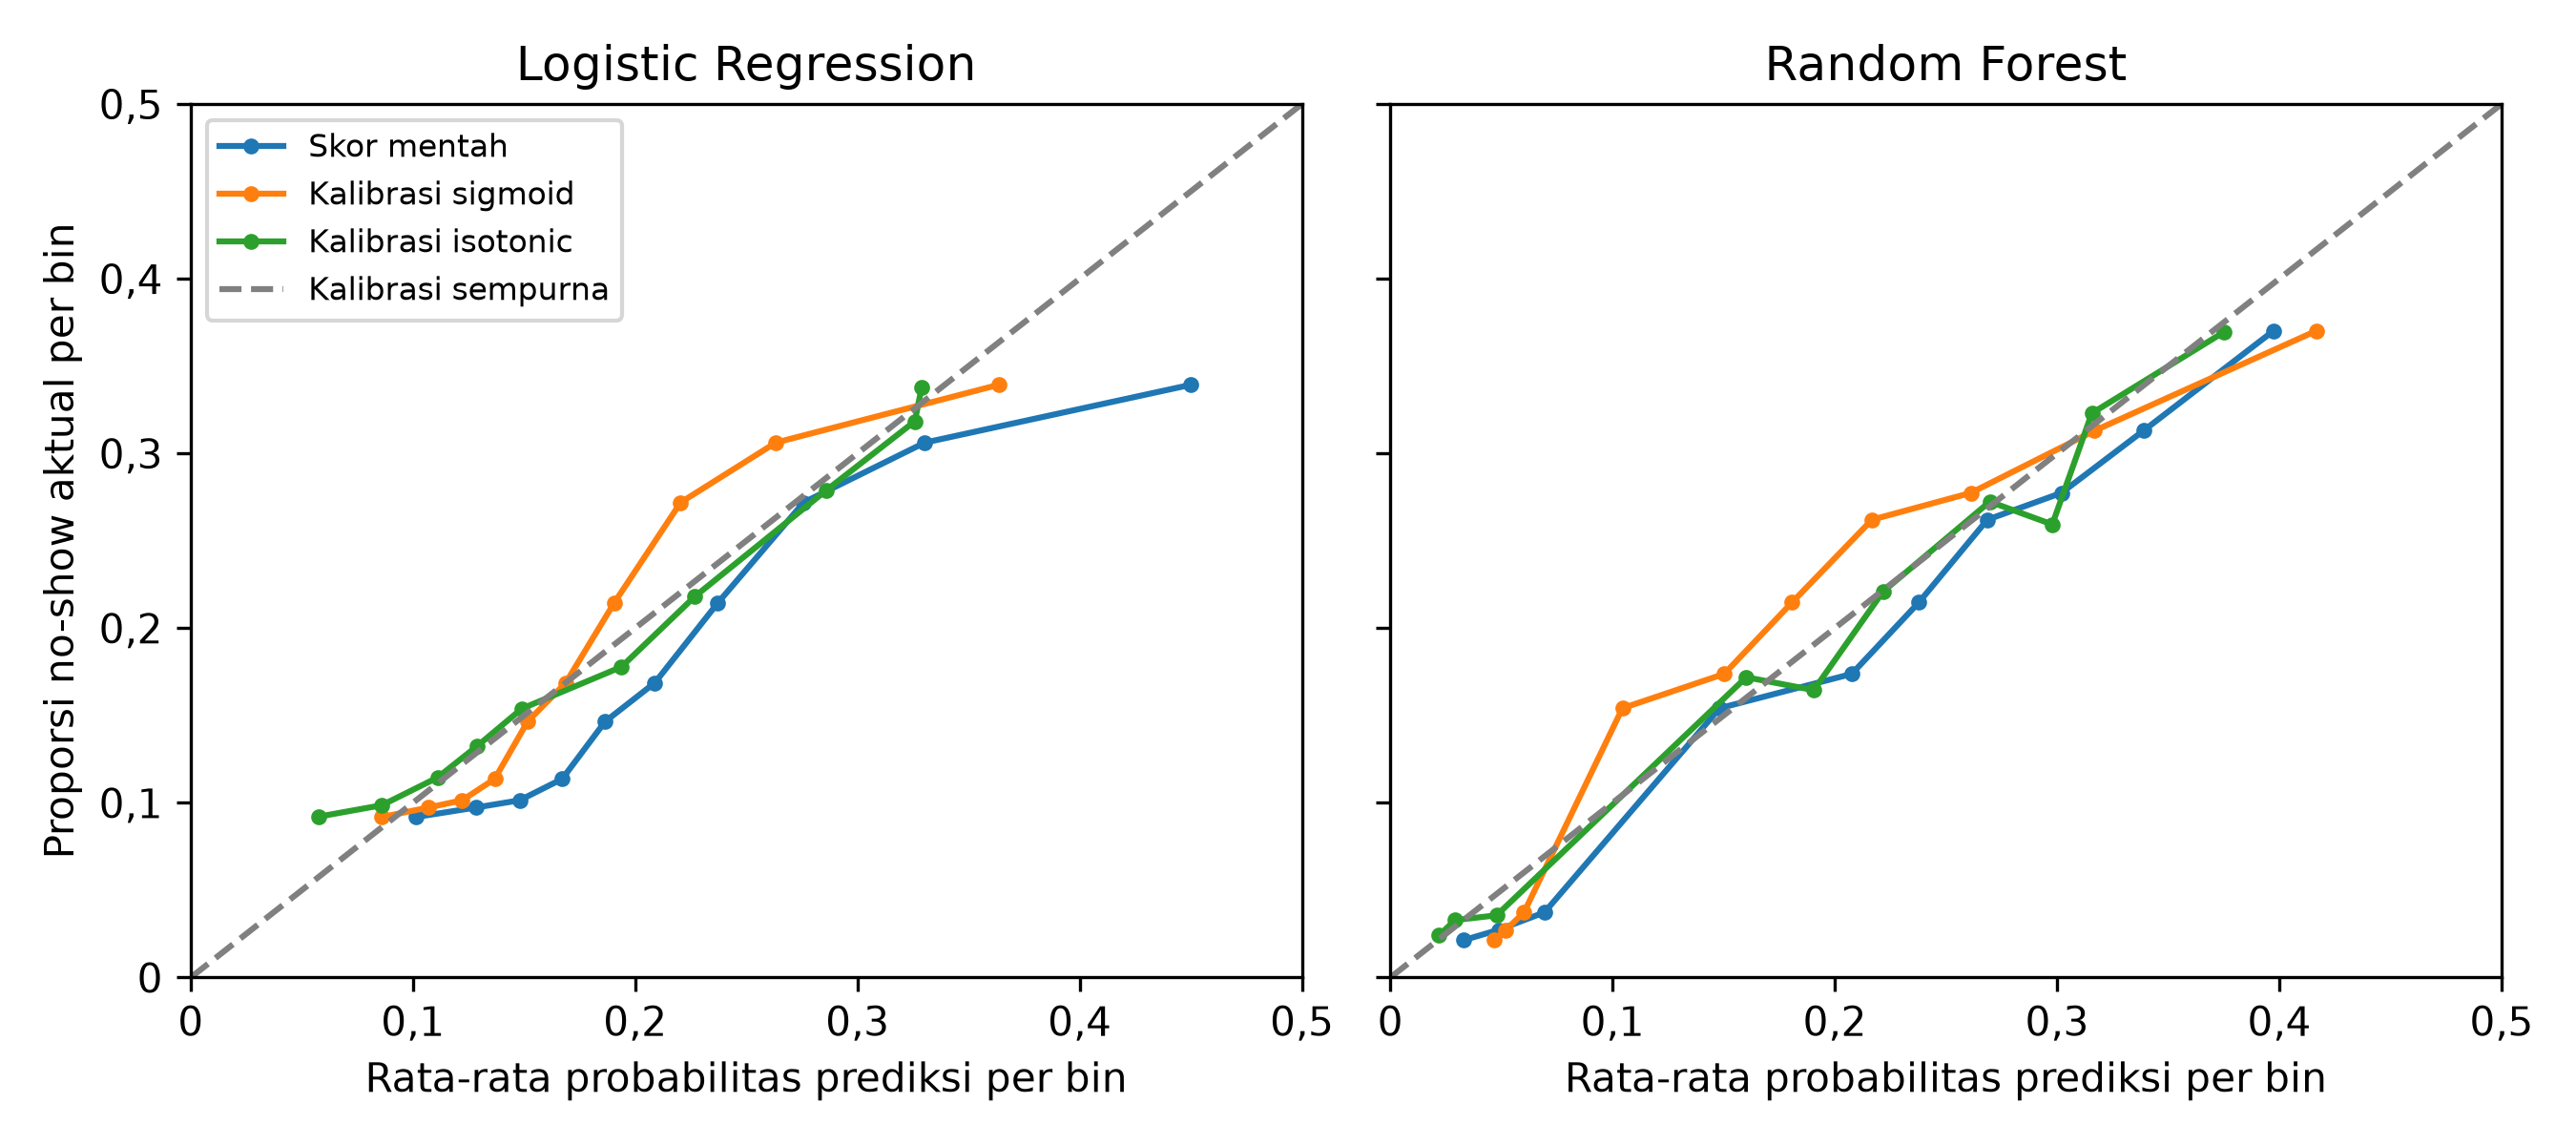

In [5]:
from IPython.display import Image, display
for f in ["pr_curves.png", "precision_at_k.png", "reliability.png"]:
    display(Image(filename=str(FIG / f), width=520))